# Phase 6: Model Interpretability and Business Insights
## Customer Churn Prediction System

This notebook investigates the inner mechanics of the production churn model using SHAP (SHapley Additive exPlanations) and permutation importance, providing global feature rankings and individual customer attributions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from churn_prediction.config import PROCESSED_DATA_DIR, MODELS_DIR, FIGURES_DIR
from churn_prediction.model_inference import load_model_bundle, ChurnPredictor
from churn_prediction.interpretability import (
    compute_shap_explanations,
    generate_global_shap_plots,
    explain_single_customer,
    get_preprocessed_features,
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
%matplotlib inline

### 1. Ingestion of Model Bundle and Test Data

In [2]:
bundle = load_model_bundle()
pipeline = bundle["pipeline"]
threshold = bundle["threshold"]

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df.drop(columns=["Churn Value"])
y_test = test_df["Churn Value"]

print(f"Loaded Pipeline with threshold: {threshold:.2f}")
print(f"Test samples: {X_test.shape[0]} rows, {X_test.shape[1]} features")

Loaded Pipeline with threshold: 0.30
Test samples: 1409 rows, 19 features


### 2. Global Interpretability via SHAP Values

In [3]:
sample_size = 250
X_sample = X_test.head(sample_size)

shap_values, feature_names = compute_shap_explanations(pipeline, X_sample)
print(f"Computed SHAP values for {sample_size} test samples across {len(feature_names)} transformed features.")

Computed SHAP values for 250 test samples across 46 transformed features.


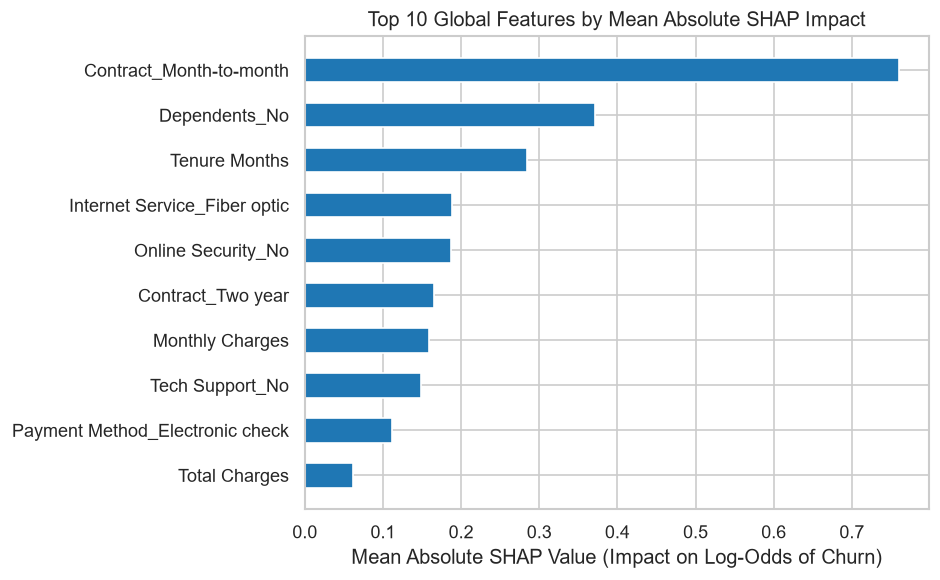

In [4]:
# Global Feature Importance Bar Chart
vals = shap_values.values
if len(vals.shape) == 3 and vals.shape[-1] == 2:
    vals = vals[:, :, 1]

mean_abs_shap = np.abs(vals).mean(axis=0)
top_idx = np.argsort(mean_abs_shap)[::-1][:10]

fig, ax = plt.subplots(figsize=(8, 5))
y_pos = np.arange(len(top_idx))[::-1]
ax.barh(y_pos, mean_abs_shap[top_idx], color="#1f77b4", height=0.55)
ax.set_yticks(y_pos)
ax.set_yticklabels([feature_names[i] for i in top_idx])
ax.set_xlabel("Mean Absolute SHAP Value (Impact on Log-Odds of Churn)")
ax.set_title("Top 10 Global Features by Mean Absolute SHAP Impact")
plt.tight_layout()
plt.show()

### 3. Local Customer Case Studies (Patient-Level Attributions)

In [5]:
# Case 1: High-risk customer
high_risk_record = X_test.loc[[test_df[test_df["Churn Value"] == 1].index[0]]]
exp_high = explain_single_customer(pipeline, high_risk_record, customer_id="High-Risk Customer")

print(f"Predicted Churn Probability: {exp_high['churn_probability']:.1%}")
print("\nTop Risk Drivers (Pushing towards Churn):")
for r in exp_high["top_risk_drivers"]:
    print(f"  + {r['Feature']}: {r['SHAP Value']:+.3f}")

print("\nTop Retention Anchors (Pushing towards Staying):")
for r in exp_high["top_retention_drivers"]:
    print(f"  - {r['Feature']}: {r['SHAP Value']:+.3f}")

Predicted Churn Probability: 38.7%

Top Risk Drivers (Pushing towards Churn):

Top Retention Anchors (Pushing towards Staying):


In [6]:
# Case 2: Low-risk customer
low_risk_record = X_test.loc[[test_df[test_df["Churn Value"] == 0].index[0]]]
exp_low = explain_single_customer(pipeline, low_risk_record, customer_id="Low-Risk Customer")

print(f"Predicted Churn Probability: {exp_low['churn_probability']:.1%}")
print("\nTop Retention Anchors:")
for r in exp_low["top_retention_drivers"]:
    print(f"  - {r['Feature']}: {r['SHAP Value']:+.3f}")

Predicted Churn Probability: 4.5%

Top Retention Anchors:


### 4. Strategic Business Retention Recommendations
1. **Target the 12-Month Hazard Peak:** Create a specialized "Year 1 Loyalty Milestone" onboarding program with proactive customer care outreach at month 3 and month 9.
2. **Incentivize 1-Year Contracts:** Subsidize annual contracts by offering a free trial of premium add-ons (such as free Tech Support for 3 months) in exchange for switching away from Month-to-month terms.
3. **Frictionless Payment Transition:** Offer a $5/month statement credit for switching from manual Electronic Check to automatic credit card or ACH bank drafting.
4. **Deploy Tech Support as a Retention Armor:** Bundle Tech Support with high-tier Fiber Optic packages to arrest defection rates.